In [1]:
import os

os.environ.setdefault(
    "CUBLAS_WORKSPACE_CONFIG",
    ":4096:8"
)

from pathlib import Path
from datetime import datetime

import sys
import json
import time
import math

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

In [2]:
PROJECT_DIR = Path(
    r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca"
)

DATASET_DIR = (
    PROJECT_DIR
    / "dataset"
    / "raw"
    / "cassava_dataset"
)

CONFIGS_DIR = PROJECT_DIR / "configs"

REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR = PROJECT_DIR / "models"

EXPERIMENTS_DIR = PROJECT_DIR / "experiments"

CV_RUN_ID = "cv_cached_v1"

RUN_ID = "final_cached_v1"

CV_REPORTS_DIR = (
    REPORTS_DIR
    / "cross_validation"
    / CV_RUN_ID
)

CV_EXPERIMENTS_DIR = (
    EXPERIMENTS_DIR
    / "cross_validation"
    / CV_RUN_ID
)

FINAL_REPORTS_DIR = (
    REPORTS_DIR
    / "final"
    / RUN_ID
)

FINAL_MODELS_DIR = (
    MODELS_DIR
    / "final"
    / RUN_ID
)

FINAL_EXPERIMENTS_DIR = (
    EXPERIMENTS_DIR
    / "final"
    / RUN_ID
)

for directory in [

    FINAL_REPORTS_DIR,

    FINAL_MODELS_DIR,

    FINAL_EXPERIMENTS_DIR

]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(PROJECT_DIR)
    )

In [3]:
from src.utils import (
    set_seed,
    get_device
)

from src.experiments import save_json

from src.preprocessing import build_transforms

from src.feature_cache import (
    FEATURE_DIMS,
    CLASSIFIER_ATTRIBUTES,
    calculate_sha256,
    dataframe_fingerprint,
    create_classifier,
    release_memory
)

from src.final_training import (
    run_final_training,
    load_final_model
)

from src.metrics import calculate_class_weights

from src.dataset import CassavaDataset

In [4]:
def load_json(filepath):

    with open(

        filepath,

        "r",

        encoding="utf-8"

    ) as file:

        return json.load(file)


dataset_config = load_json(

    CONFIGS_DIR

    / "dataset_config.json"

)

cv_config = load_json(

    CONFIGS_DIR

    / "cross_validation_config.json"

)

final_config = load_json(

    CONFIGS_DIR

    / "final_training_config.json"

)

SEED = final_config["seed"]

CLASS_MAPPING = dataset_config["class_mapping"]

NUM_CLASSES = len(CLASS_MAPPING)

ARCHITECTURES = final_config["architectures"]

CACHE_DIR = (

    PROJECT_DIR

    / final_config["feature_cache_dir"]

)

DEVICE = get_device()

set_seed(SEED)

assert DEVICE.type == "cuda"

assert len(ARCHITECTURES) == 5

assert NUM_CLASSES == 5

assert final_config["epochs"] == 3

assert final_config["test_reserved"]

assert final_config["training_mode"] == (
    "cached_feature_extraction"
)

assert final_config["hyperparameters"] == (
    cv_config["hyperparameters"]
)

print("Device:", DEVICE)

print("GPU:", torch.cuda.get_device_name(0))

print("Cache:", CACHE_DIR)

display(final_config)

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
Cache: C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca\dataset\cache\features_v1


{'seed': 42,
 'architectures': ['mobilenet_v3_large',
  'efficientnet_b0',
  'resnet50',
  'vit_b_16',
  'swin_t'],
 'training_mode': 'cached_feature_extraction',
 'feature_cache_dir': 'dataset\\cache\\features_v1',
 'epochs': 3,
 'batch_size': 32,
 'mixed_precision': False,
 'optimizer': 'AdamW',
 'scheduler': None,
 'augmentation': False,
 'class_weighting': True,
 'training_split': 'development',
 'num_training_images': 18187,
 'hyperparameters': {'mobilenet_v3_large': {'classifier_lr': 0.0007661100707771367,
   'weight_decay': 2.9380279387035354e-06,
   'dropout': 0.062397808134481064,
   'source': 'hyperband_feature_extraction'},
  'efficientnet_b0': {'classifier_lr': 0.001,
   'weight_decay': 0.0001,
   'dropout': 0.2,
   'source': 'baseline_feature_extraction'},
  'resnet50': {'classifier_lr': 0.001,
   'weight_decay': 0.0001,
   'dropout': 0.2,
   'source': 'baseline_feature_extraction'},
  'vit_b_16': {'classifier_lr': 0.001,
   'weight_decay': 0.0001,
   'dropout': 0.2,
   's

In [5]:
cv_summary = load_json(

    CV_EXPERIMENTS_DIR

    / "cross_validation_summary.json"

)

df_cv_summary = pd.read_csv(

    CV_REPORTS_DIR

    / "cross_validation_summary.csv"

)

assert cv_summary["status"] == "completed"

assert cv_summary["completed_trainings"] == 15

assert cv_summary["n_splits"] == 3

assert not cv_summary["test_used"]

assert len(df_cv_summary) == 5

assert (

    df_cv_summary["folds_completed"] == 3

).all()

display(

    df_cv_summary[[

        "architecture",

        "f1_macro_mean",

        "f1_macro_std",

        "folds_completed"

    ]].round(4)

)

print("Cross-Validation verificada.")

,architecture,f1_macro_mean,f1_macro_std,folds_completed
0,swin_t,0.6212,0.0112,3
1,efficientnet_b0,0.5869,0.0046,3
2,mobilenet_v3_large,0.5847,0.0028,3
3,vit_b_16,0.5816,0.0038,3
4,resnet50,0.5789,0.0074,3


Cross-Validation verificada.


In [6]:
df_splits = pd.read_csv(

    REPORTS_DIR

    / "dataset_splits.csv"

)

df_development = df_splits[

    df_splits["split"] == "development"

].reset_index(drop=True)

df_test = df_splits[

    df_splits["split"] == "test"

].reset_index(drop=True)

assert len(df_development) == 18187

assert len(df_test) == 3210

assert df_splits["filepath"].is_unique

assert df_splits["sha256"].notna().all()

assert set(

    df_development["sha256"]

).isdisjoint(

    df_test["sha256"]

)

assert len(df_development) == (

    final_config["num_training_images"]

)

print("Development:", len(df_development))

print("Test reservado:", len(df_test))

Development: 18187
Test reservado: 3210


In [7]:
df_distribution = pd.crosstab(

    df_splits["class"],

    df_splits["split"]

)

df_distribution["total"] = (

    df_distribution.sum(axis=1)

)

df_distribution["development_pct"] = (

    df_distribution["development"]

    / df_distribution["total"]

    * 100

)

df_distribution["test_pct"] = (

    df_distribution["test"]

    / df_distribution["total"]

    * 100

)

display(
    df_distribution.round(2)
)

df_distribution.to_csv(

    FINAL_REPORTS_DIR

    / "final_training_distribution.csv",

    encoding="utf-8-sig"

)

split,development,test,total,development_pct,test_pct
class,,,,,
bacterial_blight,924,163,1087,85.00,15.00
brown_streak_disease,1861,328,2189,85.02,14.98
green_mottle,2028,358,2386,85.00,15.00
healthy,2190,387,2577,84.98,15.02
mosaic_disease,11184,1974,13158,85.00,15.00


In [8]:
class_weights = calculate_class_weights(

    df_development,

    CLASS_MAPPING

)

df_class_weights = pd.DataFrame([

    {

        "class": class_name,

        "class_id": class_id,

        "training_images": int(

            (

                df_development["class"]

                == class_name

            ).sum()

        ),

        "class_weight": float(

            class_weights[class_id]

        )

    }

    for class_name, class_id

    in sorted(

        CLASS_MAPPING.items(),

        key=lambda item: item[1]

    )

])

display(
    df_class_weights.round(6)
)

df_class_weights.to_csv(

    FINAL_REPORTS_DIR

    / "final_class_weights.csv",

    index=False,

    encoding="utf-8-sig"

)

,class,class_id,training_images,class_weight
0,bacterial_blight,0,924,3.936580
1,brown_streak_disease,1,1861,1.954541
2,green_mottle,2,2028,1.793590
3,healthy,3,2190,1.660913
4,mosaic_disease,4,11184,0.325232


In [9]:
cache_verification = []

expected_dataframe_hash = (

    dataframe_fingerprint(

        df_development

    )

)

for model_name in ARCHITECTURES:

    cache_path = (

        CACHE_DIR

        / f"{model_name}.pth"

    )

    assert cache_path.exists(), (

        f"Caché no encontrada: {model_name}"

    )

    cache = torch.load(

        cache_path,

        map_location="cpu",

        weights_only=True

    )

    assert cache["features"].shape == (

        len(df_development),

        FEATURE_DIMS[model_name]

    )

    assert cache["metadata"]["dataframe_hash"] == (

        expected_dataframe_hash

    )

    assert cache["metadata"]["architecture"] == (

        model_name

    )

    assert cache["metadata"]["class_mapping"] == (

        CLASS_MAPPING

    )

    assert cache["filepaths"] == (

        df_development["filepath"].tolist()

    )

    assert torch.isfinite(

        cache["features"]

    ).all()

    assert cache["metadata"]["extra"]["split"] == (

        "development"

    )

    assert cache["metadata"]["extra"]["preprocessing_hash"] == (

        calculate_sha256(

            CONFIGS_DIR

            / "preprocessing_config.json"

        )

    )

    assert cache["metadata"]["extra"]["model_factory_hash"] == (

        calculate_sha256(

            PROJECT_DIR

            / "src"

            / "model_factory.py"

        )

    )

    assert cache["metadata"]["extra"]["feature_cache_hash"] == (

        calculate_sha256(

            PROJECT_DIR

            / "src"

            / "feature_cache.py"

        )

    )

    cache_verification.append({

        "architecture": model_name,

        "images": len(cache["labels"]),

        "feature_dim": cache["features"].shape[1],

        "cache_size_mib": (

            cache_path.stat().st_size

            / (1024 ** 2)

        ),

        "valid": True

    })

    del cache

df_cache_verification = pd.DataFrame(

    cache_verification

)

display(df_cache_verification)

release_memory()

,architecture,images,feature_dim,cache_size_mib,valid
0,mobilenet_v3_large,18187,960,67.409266,True
1,efficientnet_b0,18187,1280,89.610176,True
2,resnet50,18187,2048,142.892363,True
3,vit_b_16,18187,768,54.088652,True
4,swin_t,18187,768,54.088579,True


In [10]:

tracked_files = [

    REPORTS_DIR / "dataset_splits.csv",

    CONFIGS_DIR / "dataset_config.json",

    CONFIGS_DIR / "preprocessing_config.json",

    CONFIGS_DIR / "model_config.json",

    CONFIGS_DIR / "cross_validation_config.json",

    CONFIGS_DIR / "final_training_config.json",

    CV_REPORTS_DIR / "cross_validation_summary.csv",

    CV_EXPERIMENTS_DIR / "cross_validation_summary.json"

]

source_files = [

    "final_training.py",

    "feature_cache.py",

    "cached_training.py",

    "model_factory.py",

    "metrics.py",

    "data_generator.py",

    "dataset.py",

    "preprocessing.py",

    "experiments.py",

    "utils.py"

]

tracked_files.extend([

    PROJECT_DIR / "src" / filename

    for filename in source_files

])

tracked_files.extend([

    CACHE_DIR / f"{model_name}.pth"

    for model_name in ARCHITECTURES

])

experiment_signature = {

    str(filepath.relative_to(PROJECT_DIR)):

        calculate_sha256(filepath)

    for filepath in tracked_files

}

signature_path = (

    FINAL_EXPERIMENTS_DIR

    / "experiment_signature.json"

)

if signature_path.exists():

    assert load_json(signature_path) == (

        experiment_signature

    ), "La firma experimental cambió."

else:

    save_json(

        experiment_signature,

        signature_path

    )

save_json(

    final_config,

    FINAL_EXPERIMENTS_DIR

    / "final_training_config.json"

)

print(

    "Archivos verificados:",

    len(experiment_signature)

)

Archivos verificados: 23


In [11]:
steps_per_epoch = math.ceil(

    len(df_development)

    / final_config["batch_size"]

)

steps_per_model = (

    steps_per_epoch

    * final_config["epochs"]

)

total_optimizer_steps = (

    steps_per_model

    * len(ARCHITECTURES)

)

df_training_plan = pd.DataFrame([

    {

        "architecture": model_name,

        "images": len(df_development),

        "epochs": final_config["epochs"],

        "batch_size": final_config["batch_size"],

        "steps_per_epoch": steps_per_epoch,

        "total_steps": steps_per_model,

        "learning_rate": final_config[

            "hyperparameters"

        ][model_name]["classifier_lr"]

    }

    for model_name in ARCHITECTURES

])

display(df_training_plan)

print(

    "Total de actualizaciones esperadas:",

    total_optimizer_steps

)

,architecture,images,epochs,batch_size,steps_per_epoch,total_steps,learning_rate
0,mobilenet_v3_large,18187,3,32,569,1707,0.000766
1,efficientnet_b0,18187,3,32,569,1707,0.001000
2,resnet50,18187,3,32,569,1707,0.001000
3,vit_b_16,18187,3,32,569,1707,0.001000
4,swin_t,18187,3,32,569,1707,0.001000


Total de actualizaciones esperadas: 8535


In [12]:
def train_final_model(model_name):

    cache = torch.load(

        CACHE_DIR / f"{model_name}.pth",

        map_location="cpu",

        weights_only=True

    )

    try:

        result = run_final_training(

            model_name=model_name,

            cache=cache,

            df_development=df_development,

            class_mapping=CLASS_MAPPING,

            final_config=final_config,

            checkpoint_dir=(

                FINAL_MODELS_DIR

                / model_name

            ),

            report_dir=(

                FINAL_REPORTS_DIR

                / model_name

            ),

            device=DEVICE

        )

        return result

    finally:

        del cache

        release_memory()

In [13]:
final_results = []

final_errors = []

execution_start = time.perf_counter()

for model_name in ARCHITECTURES:

    print("\n" + "=" * 65)

    print("FINAL TRAINING:", model_name)

    print("=" * 65)

    try:

        result = train_final_model(

            model_name

        )

        final_results.append(result)

        pd.DataFrame(

            final_results

        ).to_csv(

            FINAL_REPORTS_DIR

            / "final_training_results.csv",

            index=False,

            encoding="utf-8-sig"

        )

    except KeyboardInterrupt:

        print("Entrenamiento interrumpido.")

        break

    except Exception as error:

        final_errors.append({

            "architecture": model_name,

            "error": str(error)

        })

        print("Error:", error)

        break

    finally:

        release_memory()

        save_json(

            final_errors,

            FINAL_EXPERIMENTS_DIR

            / "final_training_errors.json"

        )

print(

    "Tiempo de esta ejecución:",

    round(

        (time.perf_counter() - execution_start)

        / 60,

        2

    ),

    "minutos"

)

display(

    pd.DataFrame(final_results)

)


FINAL TRAINING: mobilenet_v3_large
mobilenet_v3_large | Epoch 1 | Loss: 1.0463 | Train F1: 0.5349 | 2.11 s
mobilenet_v3_large | Epoch 2 | Loss: 0.9051 | Train F1: 0.5892 | 1.55 s
mobilenet_v3_large | Epoch 3 | Loss: 0.8535 | Train F1: 0.6092 | 1.70 s
Completado: mobilenet_v3_large | 0.11 min

FINAL TRAINING: efficientnet_b0
efficientnet_b0 | Epoch 1 | Loss: 1.0902 | Train F1: 0.5182 | 1.51 s
efficientnet_b0 | Epoch 2 | Loss: 0.9529 | Train F1: 0.5753 | 1.19 s
efficientnet_b0 | Epoch 3 | Loss: 0.9089 | Train F1: 0.5943 | 1.33 s
Completado: efficientnet_b0 | 0.09 min

FINAL TRAINING: resnet50
resnet50 | Epoch 1 | Loss: 1.1659 | Train F1: 0.4944 | 1.87 s
resnet50 | Epoch 2 | Loss: 1.0006 | Train F1: 0.5626 | 1.96 s
resnet50 | Epoch 3 | Loss: 0.9525 | Train F1: 0.5776 | 1.69 s
Completado: resnet50 | 0.13 min

FINAL TRAINING: vit_b_16
vit_b_16 | Epoch 1 | Loss: 1.1015 | Train F1: 0.5055 | 1.26 s
vit_b_16 | Epoch 2 | Loss: 0.9686 | Train F1: 0.5643 | 1.18 s
vit_b_16 | Epoch 3 | Loss: 0.9399

,architecture,epochs_completed,training_images,hyperparameter_source,final_train_loss,final_train_f1_macro,optimizer_steps,total_parameters,classifier_parameters,training_seconds,total_seconds,total_minutes,classifier_path,model_path,model_size_mib,artifact_hashes,checkpoint_verified,test_used,status
0,mobilenet_v3_large,3,18187,hyperband_feature_extraction,0.853453,0.609232,1707,4208437,1236485,5.359635,6.784463,0.113074,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,16.237597,{'final_classifier.pth': 'e8c455befa99c9dc7229...,True,False,success
1,efficientnet_b0,3,18187,baseline_feature_extraction,0.908924,0.594289,1707,4013953,6405,4.029409,5.207548,0.086792,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,15.579668,{'final_classifier.pth': '056d002331c10e0155e8...,True,False,success
2,resnet50,3,18187,baseline_feature_extraction,0.952475,0.577644,1707,23518277,10245,5.529084,7.577251,0.126288,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,90.011354,{'final_classifier.pth': '4ab81f2f3e9a9902bad1...,True,False,success
3,vit_b_16,3,18187,baseline_feature_extraction,0.939906,0.577553,1707,85802501,3845,3.980055,7.800280,0.130005,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,327.359606,{'final_classifier.pth': 'a440dc407265b4fc85f2...,True,False,success
4,swin_t,3,18187,baseline_feature_extraction,0.878484,0.610834,1707,27523199,3845,4.113421,7.049696,0.117495,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,105.267811,{'final_classifier.pth': 'f2dacef157545d66cdb4...,True,False,success


In [14]:
df_final_results = pd.read_csv(

    FINAL_REPORTS_DIR

    / "final_training_results.csv"

)

assert len(df_final_results) == 5

assert df_final_results["architecture"].is_unique

assert set(

    df_final_results["architecture"]

) == set(ARCHITECTURES)

assert (

    df_final_results["status"] == "success"

).all()

display(

    df_final_results[[

        "architecture",

        "epochs_completed",

        "training_images",

        "final_train_loss",

        "final_train_f1_macro",

        "optimizer_steps",

        "total_minutes",

        "model_size_mib"

    ]].round(4)

)

,architecture,epochs_completed,training_images,final_train_loss,final_train_f1_macro,optimizer_steps,total_minutes,model_size_mib
0,mobilenet_v3_large,3,18187,0.8535,0.6092,1707,0.1131,16.2376
1,efficientnet_b0,3,18187,0.9089,0.5943,1707,0.0868,15.5797
2,resnet50,3,18187,0.9525,0.5776,1707,0.1263,90.0114
3,vit_b_16,3,18187,0.9399,0.5776,1707,0.1300,327.3596
4,swin_t,3,18187,0.8785,0.6108,1707,0.1175,105.2678


In [15]:
df_final_comparison = df_cv_summary[[

    "architecture",

    "family",

    "f1_macro_mean",

    "f1_macro_std"

]].merge(

    df_final_results[[

        "architecture",

        "final_train_f1_macro",

        "final_train_loss",

        "total_minutes",

        "model_size_mib"

    ]],

    on="architecture",

    validate="one_to_one"

)

df_final_comparison = (

    df_final_comparison.sort_values(

        "f1_macro_mean",

        ascending=False

    )

)

display(

    df_final_comparison.round(4)

)

df_final_comparison.to_csv(

    FINAL_REPORTS_DIR

    / "cv_final_training_comparison.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,family,f1_macro_mean,f1_macro_std,final_train_f1_macro,final_train_loss,total_minutes,model_size_mib
0,swin_t,Transformer,0.6212,0.0112,0.6108,0.8785,0.1175,105.2678
1,efficientnet_b0,CNN,0.5869,0.0046,0.5943,0.9089,0.0868,15.5797
2,mobilenet_v3_large,CNN,0.5847,0.0028,0.6092,0.8535,0.1131,16.2376
3,vit_b_16,Transformer,0.5816,0.0038,0.5776,0.9399,0.1300,327.3596
4,resnet50,CNN,0.5789,0.0074,0.5776,0.9525,0.1263,90.0114


In [16]:
all_histories = []

for model_name in ARCHITECTURES:

    history = pd.read_csv(

        FINAL_REPORTS_DIR

        / model_name

        / "history.csv"

    )

    assert len(history) == 3

    assert (

        history["train_optimizer_steps"]

        == steps_per_epoch

    ).all()

    history.insert(

        0,

        "architecture",

        model_name

    )

    all_histories.append(history)

df_final_history = pd.concat(

    all_histories,

    ignore_index=True

)

assert len(df_final_history) == 15

df_final_history.to_csv(

    FINAL_REPORTS_DIR

    / "final_training_history.csv",

    index=False,

    encoding="utf-8-sig"

)

display(

    df_final_history[[

        "architecture",

        "epoch",

        "train_loss",

        "train_f1_macro",

        "train_seconds",

        "train_optimizer_steps"

    ]].round(4)

)

,architecture,epoch,train_loss,train_f1_macro,train_seconds,train_optimizer_steps
0,mobilenet_v3_large,1,1.0463,0.5349,2.1074,569
1,mobilenet_v3_large,2,0.9051,0.5892,1.5472,569
2,mobilenet_v3_large,3,0.8535,0.6092,1.7029,569
3,efficientnet_b0,1,1.0902,0.5182,1.5109,569
4,efficientnet_b0,2,0.9529,0.5753,1.1851,569
5,efficientnet_b0,3,0.9089,0.5943,1.3306,569
6,resnet50,1,1.1659,0.4944,1.8740,569
7,resnet50,2,1.0006,0.5626,1.9578,569
8,resnet50,3,0.9525,0.5776,1.6940,569
9,vit_b_16,1,1.1015,0.5055,1.2611,569


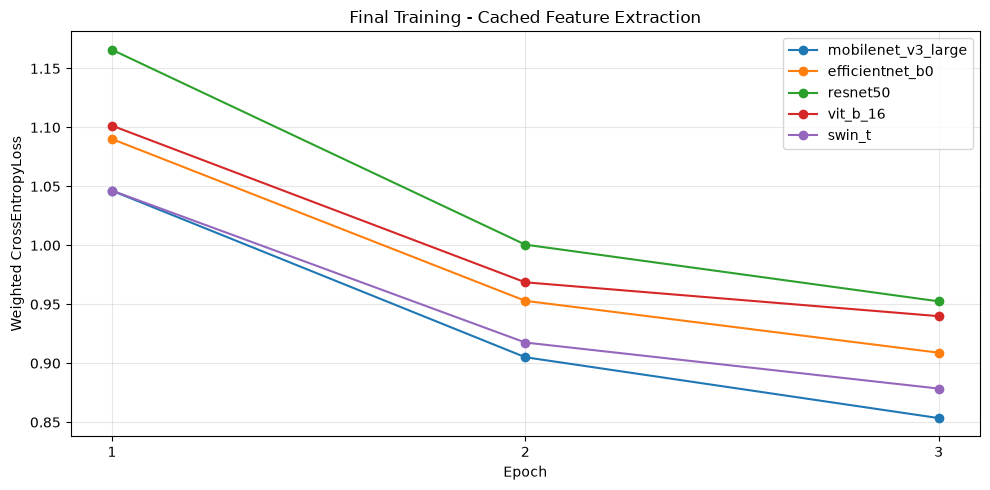

In [17]:
plt.figure(figsize=(10, 5))

for model_name in ARCHITECTURES:

    history = df_final_history[

        df_final_history["architecture"]

        == model_name

    ]

    plt.plot(

        history["epoch"],

        history["train_loss"],

        marker="o",

        label=model_name

    )

plt.xlabel("Epoch")

plt.ylabel("Weighted CrossEntropyLoss")

plt.title("Final Training - Cached Feature Extraction")

plt.xticks([1, 2, 3])

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    FINAL_REPORTS_DIR

    / "final_training_loss.png",

    dpi=150

)

plt.show()

In [18]:
_, eval_transform = build_transforms(

    CONFIGS_DIR

    / "preprocessing_config.json"

)

sample_indices = np.linspace(

    0,

    len(df_development) - 1,

    num=8,

    dtype=int

)

sample_dataset = CassavaDataset(

    dataframe=df_development.iloc[

        sample_indices

    ].reset_index(drop=True),

    dataset_dir=DATASET_DIR,

    class_mapping=CLASS_MAPPING,

    transform=eval_transform

)

sample_images = torch.stack([

    sample_dataset[i][0]

    for i in range(len(sample_dataset))

]).to(DEVICE)

verification_results = []

for model_name in ARCHITECTURES:

    model_dir = (

        FINAL_MODELS_DIR

        / model_name

    )

    cache = torch.load(

        CACHE_DIR / f"{model_name}.pth",

        map_location="cpu",

        weights_only=True

    )

    model, metadata = load_final_model(

        model_dir / "final_model.pth",

        DEVICE

    )

    classifier_checkpoint = torch.load(

        model_dir / "final_classifier.pth",

        map_location="cpu",

        weights_only=True

    )

    classifier = create_classifier(

        model_name=model_name,

        num_classes=NUM_CLASSES,

        dropout=metadata["dropout"]

    ).to(DEVICE)

    classifier.load_state_dict(

        classifier_checkpoint[

            "classifier_state_dict"

        ],

        strict=True

    )

    classifier.eval()

    with torch.inference_mode():

        cached_features = cache["features"][

            sample_indices

        ].to(DEVICE)

        cached_logits = classifier(

            cached_features

        )

        # AMP solo en el extractor,
        # igual que durante Feature Caching.

        attribute = CLASSIFIER_ATTRIBUTES[

            model_name

        ]

        model_classifier = getattr(

            model,

            attribute

        )

        setattr(

            model,

            attribute,

            torch.nn.Identity()

        )

        try:

            with torch.autocast(

                device_type=DEVICE.type,

                dtype=torch.float16,

                enabled=cache["metadata"][

                    "mixed_precision"

                ]

            ):

                direct_features = model(

                    sample_images

                ).float()

        finally:

            setattr(

                model,

                attribute,

                model_classifier

            )

        direct_logits = model_classifier(

            direct_features

        )

        cached_probs = torch.softmax(

            cached_logits,

            dim=1

        )

        direct_probs = torch.softmax(

            direct_logits,

            dim=1

        )

        max_difference = (

            cached_probs - direct_probs

        ).abs().max().item()

        agreement = (

            cached_probs.argmax(dim=1)

            == direct_probs.argmax(dim=1)

        ).float().mean().item()

        assert torch.isfinite(

            direct_probs

        ).all()

        assert direct_probs.shape == (

            len(sample_indices),

            NUM_CLASSES

        )

        probabilities_close = torch.allclose(

            cached_probs,

            direct_probs,

            atol=0.01,

            rtol=0.01

        )

    verification_results.append({

        "architecture": model_name,

        "samples_verified": len(sample_indices),

        "max_probability_difference": max_difference,

        "prediction_agreement": agreement,

        "probabilities_close": probabilities_close,

        "checkpoint_load_success": True

    })

    del model

    del classifier

    del cache

    del model_classifier

    release_memory()

df_model_verification = pd.DataFrame(

    verification_results

)

display(

    df_model_verification.round(6)

)

df_model_verification.to_csv(

    FINAL_REPORTS_DIR

    / "final_model_verification.csv",

    index=False,

    encoding="utf-8-sig"

)

del sample_images

release_memory()

,architecture,samples_verified,max_probability_difference,prediction_agreement,probabilities_close,checkpoint_load_success
0,mobilenet_v3_large,8,0.001104,1.0,True,True
1,efficientnet_b0,8,0.000599,1.0,True,True
2,resnet50,8,0.000756,1.0,True,True
3,vit_b_16,8,0.000341,1.0,True,True
4,swin_t,8,0.000549,1.0,True,True


In [19]:
centralized_model_registry = {

    "run_id": RUN_ID,

    "approach": "centralized",

    "training_mode": "cached_feature_extraction",

    "num_models": len(ARCHITECTURES),

    "num_classes": NUM_CLASSES,

    "class_mapping": CLASS_MAPPING,

    "image_size": [224, 224],

    "preprocessing_config": (

        "configs/preprocessing_config.json"

    ),

    "test_evaluation_pending": True,

    "models": {}

}

for model_name in ARCHITECTURES:

    model_dir = (

        FINAL_MODELS_DIR

        / model_name

    )

    centralized_model_registry["models"][

        model_name

    ] = {

        "model_path": str(

            (

                model_dir / "final_model.pth"

            ).relative_to(PROJECT_DIR)

        ),

        "classifier_path": str(

            (

                model_dir / "final_classifier.pth"

            ).relative_to(PROJECT_DIR)

        ),

        "feature_dim": FEATURE_DIMS[model_name],

        "dropout": final_config[

            "hyperparameters"

        ][model_name]["dropout"],

        "epochs": final_config["epochs"]

    }

save_json(

    centralized_model_registry,

    CONFIGS_DIR

    / "centralized_model_registry.json"

)

display(centralized_model_registry)

{'run_id': 'final_cached_v1',
 'approach': 'centralized',
 'training_mode': 'cached_feature_extraction',
 'num_models': 5,
 'num_classes': 5,
 'class_mapping': {'bacterial_blight': 0,
  'brown_streak_disease': 1,
  'green_mottle': 2,
  'healthy': 3,
  'mosaic_disease': 4},
 'image_size': [224, 224],
 'preprocessing_config': 'configs/preprocessing_config.json',
 'test_evaluation_pending': True,
 'models': {'mobilenet_v3_large': {'model_path': 'models\\final\\final_cached_v1\\mobilenet_v3_large\\final_model.pth',
   'classifier_path': 'models\\final\\final_cached_v1\\mobilenet_v3_large\\final_classifier.pth',
   'feature_dim': 960,
   'dropout': 0.062397808134481064,
   'epochs': 3},
  'efficientnet_b0': {'model_path': 'models\\final\\final_cached_v1\\efficientnet_b0\\final_model.pth',
   'classifier_path': 'models\\final\\final_cached_v1\\efficientnet_b0\\final_classifier.pth',
   'feature_dim': 1280,
   'dropout': 0.2,
   'epochs': 3},
  'resnet50': {'model_path': 'models\\final\\final

In [20]:
federated_training_config = {

    "experiment_name": "cached_federated_training",

    "run_id": "federated_cached_v1",

    "seed": SEED,

    "architectures": ARCHITECTURES,

    "algorithm": "FedAvg",

    "simulation": True,

    "num_servers": 1,

    "num_clients": 2,

    "client_ids": [1, 2],

    "rounds": 3,

    "local_epochs": 1,

    "batch_size": final_config["batch_size"],

    "num_workers": 0,

    "optimizer": "AdamW",

    "mixed_precision": False,

    "feature_caching": True,

    "freeze_backbone": True,

    "partial_finetuning": False,

    "aggregation": "sample_weighted",

    "class_weight_source": "global_development",

    "client_optimizer_reset_each_round": True,

    "initialization": "fresh_classifier",

    "hyperparameters": final_config["hyperparameters"],

    "feature_cache_dir": final_config["feature_cache_dir"],

    "federated_splits": "reports/federated_splits.csv",

    "centralized_run_id": RUN_ID,

    "training_split": "development",

    "test_reserved": True,

    "evaluate_test_after_training": False

}

save_json(

    federated_training_config,

    CONFIGS_DIR

    / "federated_training_config.json"

)

display(federated_training_config)

{'experiment_name': 'cached_federated_training',
 'run_id': 'federated_cached_v1',
 'seed': 42,
 'architectures': ['mobilenet_v3_large',
  'efficientnet_b0',
  'resnet50',
  'vit_b_16',
  'swin_t'],
 'algorithm': 'FedAvg',
 'simulation': True,
 'num_servers': 1,
 'num_clients': 2,
 'client_ids': [1, 2],
 'rounds': 3,
 'local_epochs': 1,
 'batch_size': 32,
 'num_workers': 0,
 'optimizer': 'AdamW',
 'mixed_precision': False,
 'feature_caching': True,
 'freeze_backbone': True,
 'partial_finetuning': False,
 'aggregation': 'sample_weighted',
 'class_weight_source': 'global_development',
 'client_optimizer_reset_each_round': True,
 'initialization': 'fresh_classifier',
 'hyperparameters': {'mobilenet_v3_large': {'classifier_lr': 0.0007661100707771367,
   'weight_decay': 2.9380279387035354e-06,
   'dropout': 0.062397808134481064,
   'source': 'hyperband_feature_extraction'},
  'efficientnet_b0': {'classifier_lr': 0.001,
   'weight_decay': 0.0001,
   'dropout': 0.2,
   'source': 'baseline_fea

In [21]:
assert len(df_final_results) == 5

assert (

    df_final_results["epochs_completed"]

    == final_config["epochs"]

).all()

assert (

    df_final_results["training_images"]

    == len(df_development)

).all()

assert (

    df_final_results["optimizer_steps"]

    == steps_per_model

).all()

assert (

    df_final_results["optimizer_steps"].sum()

    == total_optimizer_steps

)

assert (

    df_final_results["checkpoint_verified"]

).all()

assert not (

    df_final_results["test_used"]

).any()

assert len(df_model_verification) == 5

assert (

    df_model_verification["checkpoint_load_success"]

).all()

assert (

    df_model_verification["probabilities_close"]

).all(), "Revisar equivalencia de los modelos."

assert len(

    centralized_model_registry["models"]

) == 5

print(

    "Entrenamiento definitivo verificado correctamente."

)

Entrenamiento definitivo verificado correctamente.


In [22]:
final_summary = {

    "phase": "phase_2_part_7",

    "experiment": "final_training",

    "run_id": RUN_ID,

    "status": "completed",

    "architectures": 5,

    "cnn_architectures": 3,

    "transformer_architectures": 2,

    "centralized_models_saved": 5,

    "classifier_checkpoints_saved": 5,

    "training_images": len(df_development),

    "test_images_reserved": len(df_test),

    "epochs_per_model": final_config["epochs"],

    "total_epochs": int(

        df_final_results["epochs_completed"].sum()

    ),

    "expected_optimizer_steps": total_optimizer_steps,

    "actual_optimizer_steps": int(

        df_final_results["optimizer_steps"].sum()

    ),

    "feature_caching": True,

    "partial_finetuning": False,

    "augmentation": False,

    "mixed_precision_training": False,

    "checkpoint_selection": "last_epoch",

    "training_minutes": float(

        df_final_results["training_seconds"].sum()

        / 60

    ),

    "total_minutes": float(

        df_final_results["total_minutes"].sum()

    ),

    "total_model_size_mib": float(

        df_final_results["model_size_mib"].sum()

    ),

    "models_verified": int(

        df_model_verification[

            "checkpoint_load_success"

        ].sum()

    ),

    "model_registry_generated": True,

    "federated_config_generated": True,

    "test_used": False,

    "test_evaluation_deferred_to": "phase_4",

    "timestamp": datetime.now().isoformat()

}

save_json(

    final_summary,

    FINAL_EXPERIMENTS_DIR

    / "final_training_summary.json"

)

display(final_summary)

print("=" * 65)

print("FASE 2 - PARTE 7 COMPLETADA")

print("FASE 2 - ENTRENAMIENTO INICIAL Y OPTIMIZACIÓN COMPLETADA")

print("=" * 65)

release_memory()

{'phase': 'phase_2_part_7',
 'experiment': 'final_training',
 'run_id': 'final_cached_v1',
 'status': 'completed',
 'architectures': 5,
 'cnn_architectures': 3,
 'transformer_architectures': 2,
 'centralized_models_saved': 5,
 'classifier_checkpoints_saved': 5,
 'training_images': 18187,
 'test_images_reserved': 3210,
 'epochs_per_model': 3,
 'total_epochs': 15,
 'expected_optimizer_steps': 8535,
 'actual_optimizer_steps': 8535,
 'feature_caching': True,
 'partial_finetuning': False,
 'augmentation': False,
 'mixed_precision_training': False,
 'checkpoint_selection': 'last_epoch',
 'training_minutes': 0.3835267283333451,
 'total_minutes': 0.573653956666567,
 'total_model_size_mib': 554.4560356140137,
 'models_verified': 5,
 'model_registry_generated': True,
 'federated_config_generated': True,
 'test_used': False,
 'test_evaluation_deferred_to': 'phase_4',
 'timestamp': '2026-11-26T02:00:21.104700'}

FASE 2 - PARTE 7 COMPLETADA
FASE 2 - ENTRENAMIENTO INICIAL Y OPTIMIZACIÓN COMPLETADA
